# Ariketa 3.1 — Zer da sailkatzea? + Erabaki-zuhaitzak



## 📝 Nola egin notebook hau — 3 modu

- 🟢 **KOMENTATU:** kodea emanda dago; `#`-aren ondoren azaldu lerro bakoitzak zer egiten duen.
- 🟡 **HUTSUNEAK BETE:** `____` dauden tokiak osatu behar dituzu.
- 🔴 **ARIKETA GEHIGARRIA:** kodea zerotik idatzi (azkarrentzat / etxerako).

## 0. Prestaketa 🟢

> Zuhaitzek **ez dute eskalatzea behar** (2. saioan sartuko dugu StandardScaler).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = sns.load_dataset('titanic')  # Titanic dataset-a kargatu (891 errenkada)
d = df[['survived','pclass','sex','age','fare','embarked']].copy()  # erabiliko ditugun 6 zutabeak bakarrik, kopia batean
d['age'] = d['age'].fillna(d['age'].median())  # age-ren nuluak medianarekin bete
d['embarked'] = d['embarked'].fillna(d['embarked'].mode()[0])  # embarked-en nuluak modarekin (S) bete
y = d['survived']  # helburua (y): bizirik atera zen (1) ala ez (0)
X = pd.get_dummies(d.drop(columns=['survived']), columns=['sex','embarked'], drop_first=True)  # X: gainerakoak; sex eta embarked one-hot (lehenengoa kenduta)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # %80 train / %20 test, klase-proportzioa mantenduz
print('Prest. Train:', X_train.shape[0], '| Test:', X_test.shape[0])  # bi multzoen errenkada kopurua

Prest. Train: 712 | Test: 179


## 1.1 — Sailkatzea kategoria bat iragartzea da

Titanic-en `survived` (0/1) iragartzen dugu → sailkapen **binarioa**.

## 1.2 — Erabaki-zuhaitzak punta-puntara

### a) Lehen eredua: zuhaitz bat entrenatu 🟢

In [2]:
arbola = DecisionTreeClassifier(random_state=42)  # mugarik gabeko zuhaitza sortu (random_state -> emaitza errepikagarria)
arbola.fit(X_train, y_train)  # train datuekin entrenatu: split-ak ikasi
print('Accuracy:', round(arbola.score(X_test, y_test), 3))  # test-eko asmatze-tasa (zuzen sailkatutakoak / guztiak)

from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, arbola.predict(X_test)))  # [[TN FP] [FN TP]]: diagonala = asmatzeak, bestea = erroreak

Accuracy: 0.827
[[96 14]
 [17 52]]


> **Accuracy nondik dator?** Goiko taulatik: **diagonala = asmatzeak**, diagonaletik kanpo = erroreak.
5. saioan sakonduko dugu (precision, recall... eta zergatik *engainatzen* duen batzuetan accuracy-ak).

### b) Zuhaitza marraztu eta irakurri 🟢

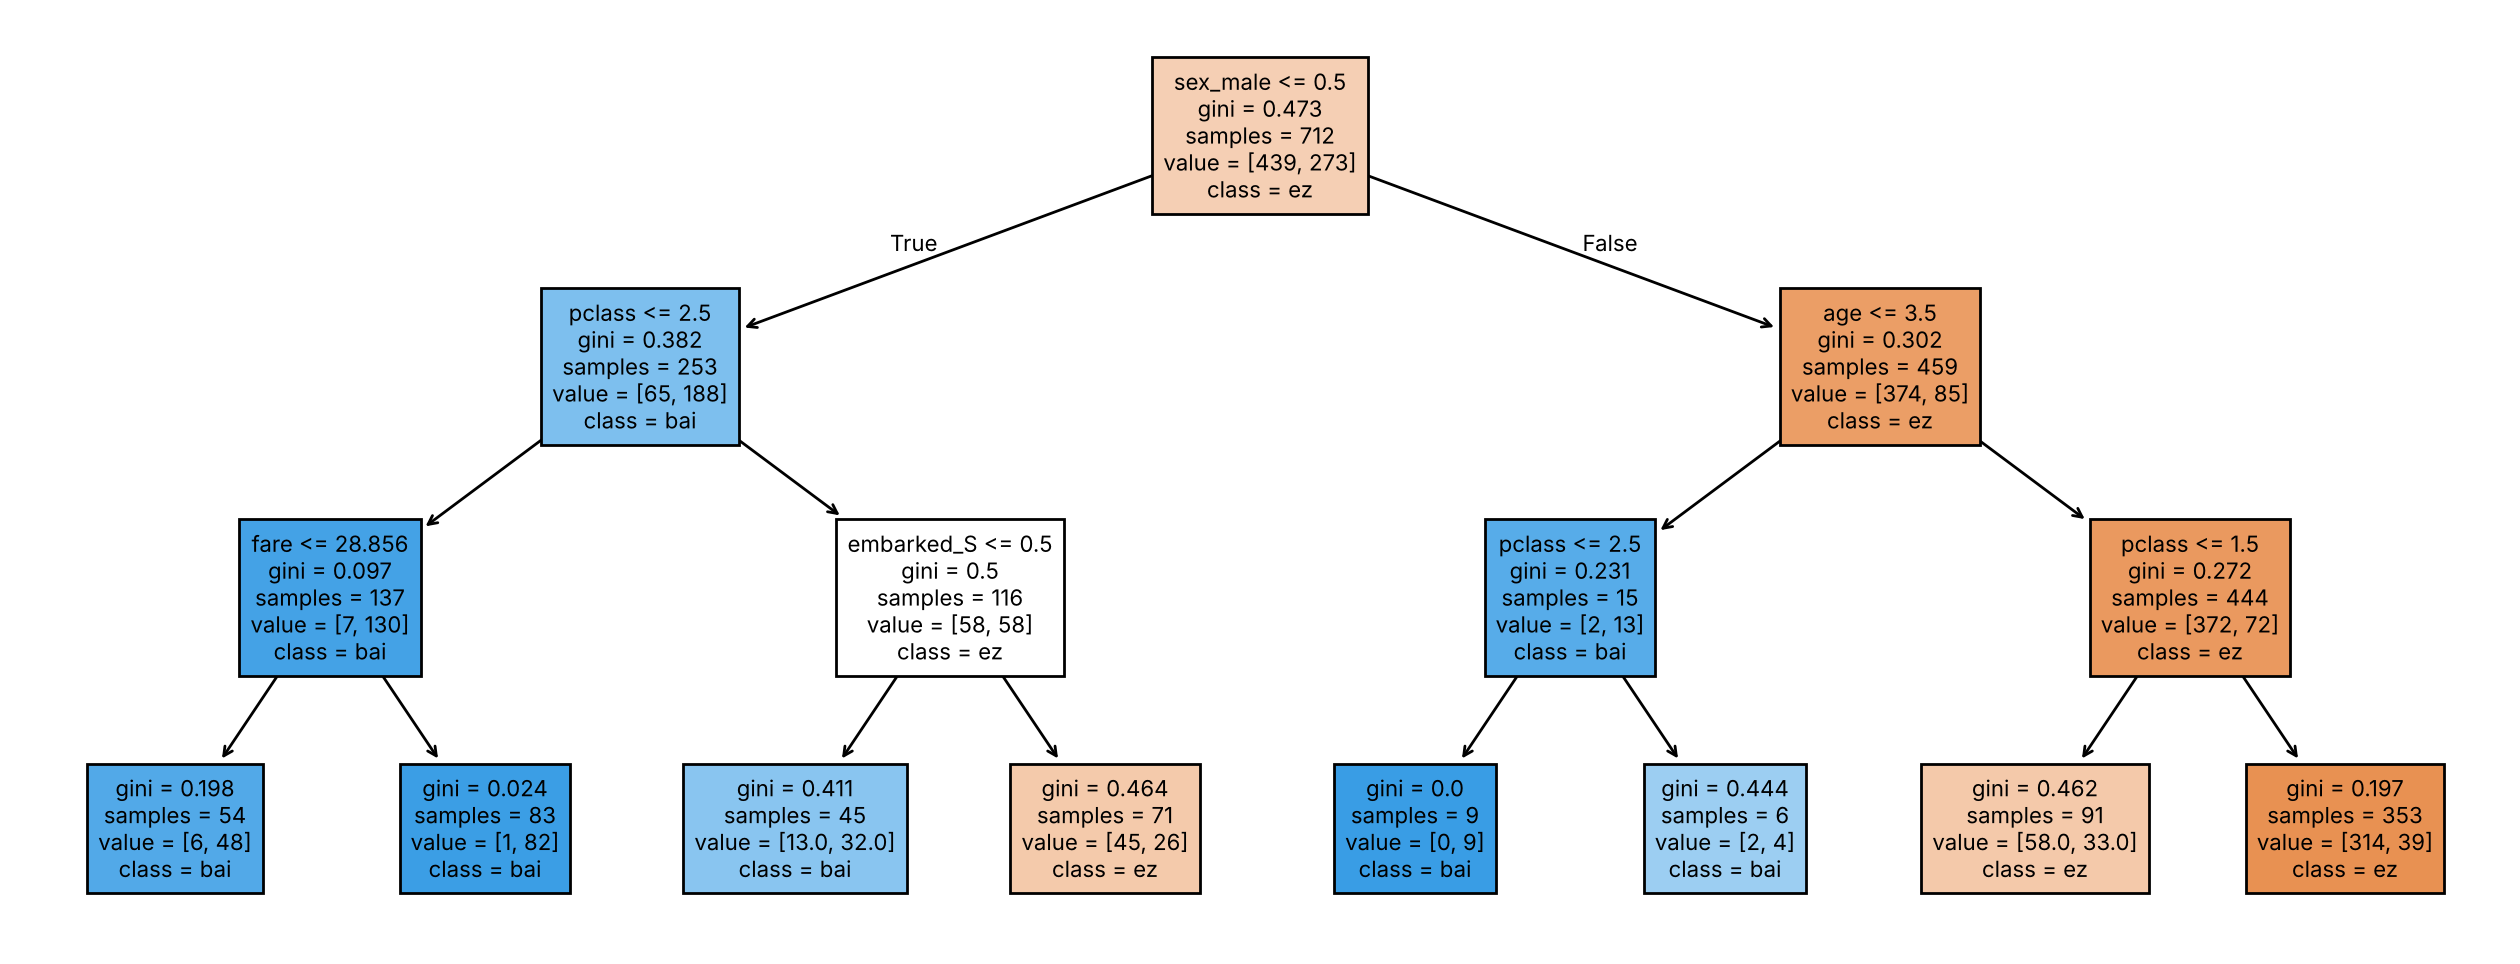

In [3]:
arbola3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)  # 3 mailako zuhaitza (irakurgarria izateko)
plt.figure(figsize=(16, 6))  # irudiaren tamaina
plot_tree(arbola3, feature_names=X.columns, class_names=['ez','bai'], filled=True, fontsize=8)  # zuhaitza marraztu: galderak, gini, samples, value eta klasea; kolorea = klase nagusia
plt.show()  # irudia erakutsi

### c) Overfitting: train vs test gap-a 🟡

**Hutsuneak bete:** `.score()`-k zer datu-multzo hartu behar du train-erako eta test-erako?

In [4]:
for md_ in [None, 3]:
    a = DecisionTreeClassifier(max_depth=md_, random_state=42).fit(X_train, y_train)
    # bete ____ : train-erako eta test-erako datuak
    print(f'max_depth={md_}: train={a.score(X_train, y_train):.3f} test={a.score(X_test, y_test):.3f}')

max_depth=None: train=0.980 test=0.827
max_depth=3: train=0.831 test=0.777


**Overfitting:** mugarik gabe %98 train / %83 test → buruz ikasi du. Gap handia = **sinadura**.

> 💡 8. saioan (detektibea) gogoratu gap hau.

### 🔴 Erronka gehigarria — Overfitting-aren kurba (KODETU ZEROTIK)

Marraztu **train eta test accuracy-a** `max_depth` 1etik 10era, kurba batean.

**Pausoak (gida):**
1. Sortu bi zerrenda huts: `train_scores`, `test_scores`.
2. `for md_ in range(1, 11):` barruan, entrenatu zuhaitz bat eta gorde train eta test score-ak.
3. `plt.plot(...)` bi aldiz (train eta test), `label`-ekin; gehitu `legend`, ardatzak eta izenburua.

# TODO: idatzi hemen zure kodea

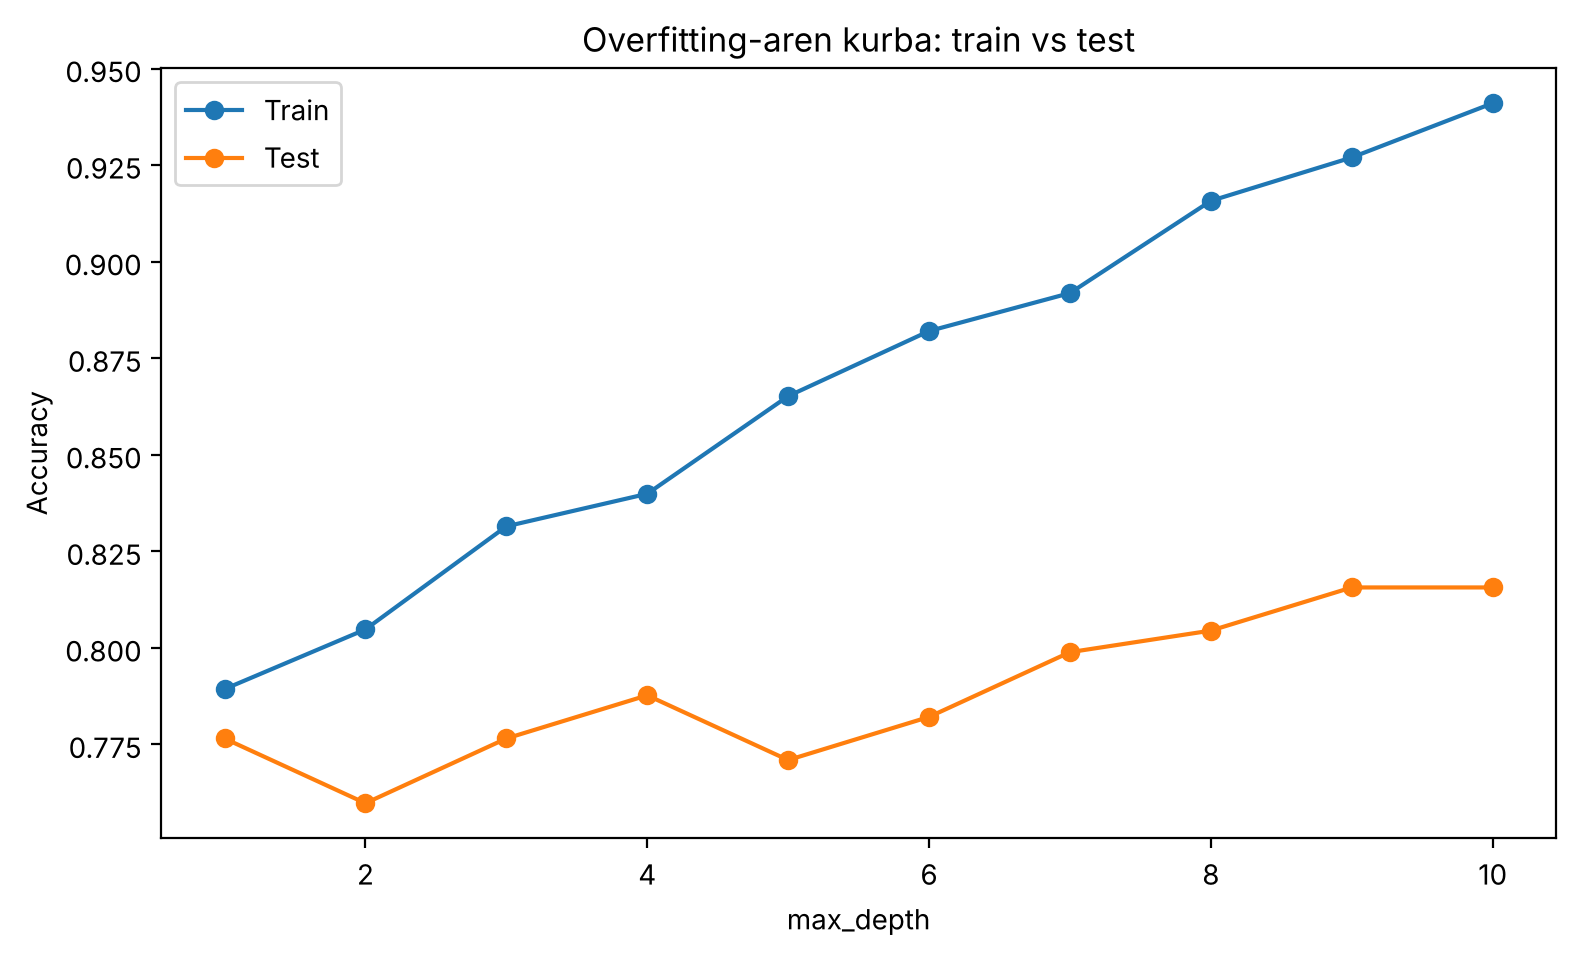

max_depth= 1  train=0.789  test=0.777  gap=0.013
max_depth= 2  train=0.805  test=0.760  gap=0.045
max_depth= 3  train=0.831  test=0.777  gap=0.055
max_depth= 4  train=0.840  test=0.788  gap=0.052
max_depth= 5  train=0.865  test=0.771  gap=0.094
max_depth= 6  train=0.882  test=0.782  gap=0.100
max_depth= 7  train=0.892  test=0.799  gap=0.093
max_depth= 8  train=0.916  test=0.804  gap=0.111
max_depth= 9  train=0.927  test=0.816  gap=0.111
max_depth=10  train=0.941  test=0.816  gap=0.125


In [5]:
# Overfitting-aren kurba: max_depth 1etik 10era
train_scores = []
test_scores = []
sakonerak = range(1, 11)

for md_ in sakonerak:
    a = DecisionTreeClassifier(max_depth=md_, random_state=42).fit(X_train, y_train)
    train_scores.append(a.score(X_train, y_train))
    test_scores.append(a.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(sakonerak, train_scores, marker='o', label='Train')
plt.plot(sakonerak, test_scores, marker='o', label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Overfitting-aren kurba: train vs test')
plt.legend()
plt.show()

for md_, tr, te in zip(sakonerak, train_scores, test_scores):
    print(f'max_depth={md_:2d}  train={tr:.3f}  test={te:.3f}  gap={tr-te:.3f}')

### Kurbaren interpretazioa

- **Train** accuracy etengabe igotzen da sakonerarekin (0.789 → 0.941): zuhaitza gero eta gehiago egokitzen zaio train-i.
- **Test** accuracy ez da era berean igotzen: 0.76–0.82 artean dabil gorabeheraka.
- **Gap-a** (train − test) handitzen doa: max_depth ≤ 4 → ~0.05; max_depth ≥ 5 → 0.09–0.125. Hortik aurrera zuhaitzak train-eko xehetasunak **buruz ikasten** ditu (overfitting).
- Mugarik gabe (`max_depth=None`) train = 0.980 eta test = 0.827: gap handia = overfitting-aren sinadura.

Ondorioa: sakonera handiagoa ≠ eredu hobea. `max_depth` txikiak (3–4) emaitza antzekoa ematen du test-ean, gap askoz txikiagoarekin eta zuhaitz irakurgarriagoarekin.

## Ondorioak

- Lehen eredua = **zuhaitza**: intuitiboa eta **marraztu/irakur daiteke**.
- Ez du **eskalatzea** behar.
- **Overfitting:** train ≫ test gap-a; `max_depth`-rekin kontrolatu.